In [6]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

# print mixomics version
packageVersion("mixOmics")

[1] ‘6.26.0’

In [7]:
DATA_DIR <- "/home/mariya/Data/pallas"
TRAIN_DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets/all-bimodal")
METH_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")
OUTPUT_DIR <- file.path(DATA_DIR, "mixOmics")

In [8]:
source("helpers.R")
train_data <- data(GEX_TRAIN_FILE, METH_TRAIN_FILE, LABELS_TRAIN_FILE)

Samples: 1200 
GEX features: 19626 
DNAm features: 187403 
Subtypes: AML, APL-PML::RARA AML, BCR::ABL1 AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, FUS::ERG AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RBM15::MKL1 AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5 P80R B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [9]:
X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,⋯,ENSG00000288825,ENSG00000288859,ENSG00000288867,ENSG00000289549,ENSG00000289604,ENSG00000290292,ENSG00000291237,ENSG00000293137,ENSG00000293560,ENSG00000310560
ALL_1005,-1.0921018,-1.092102,4.183137,4.511552,4.282654,4.883407,-1.0921018,6.758688,4.092343,4.502172,⋯,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.0921018,-1.0921018,5.802845
ALL_1019,-1.0921018,-1.092102,3.829324,4.346766,4.044038,8.397852,1.0813662,6.527599,4.946621,4.215277,⋯,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.0921018,-1.0921018,7.222508
ALL_1023,-0.7117141,-1.092102,4.697563,2.772607,3.289410,5.460184,3.6770756,3.713995,4.294493,5.125843,⋯,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-0.7504367,-1.0921018,5.699101
ALL_1026,-0.7661278,-1.092102,3.471091,4.020715,3.329187,7.784770,-0.2509482,1.954160,4.648892,4.527713,⋯,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,0.1388734,-1.0921018,6.417707
ALL_1039,-0.6517091,-1.092102,2.800514,3.260778,2.867411,7.673764,3.6597456,6.647393,4.425244,3.640900,⋯,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.0921018,-1.0921018,6.857595
ALL_1047,-0.8654887,-1.092102,4.711105,2.761678,3.654326,2.901486,-1.0093962,2.455491,3.654541,5.026756,⋯,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.092102,-1.0921018,-0.8095927,5.572824


,cg00000029,cg00000109,cg00000165,cg00000236,cg00000289,cg00000292,cg00000321,cg00000363,cg00000714,cg00000721,⋯,ch.4.194519R,ch.4.2662600F,ch.4.3427878R,ch.6.115952F,ch.6.1693624F,ch.6.92327598R,ch.7.130270068F,ch.7.1839793F,ch.9.2043201R,ch.9.31239617R
ALL_1005,0.8918,0.1351,0.5648,0.9069,0.7154,0.9421,0.6087,0.7048,0.1825,0.9242,⋯,0.0157,0.1454,0.0731,0.0645,0.0176,0.1499,0.0508,0.1041,0.0352,0.2130
ALL_1019,0.8956,0.2010,0.1756,0.8664,0.8093,0.5549,0.6161,0.6669,0.1560,0.6668,⋯,0.0169,0.0441,0.0443,0.0288,0.0526,0.0841,0.0240,0.0455,0.0234,0.0313
ALL_1023,0.9021,0.8852,0.1705,0.9225,0.7927,0.9332,0.7015,0.2693,0.1749,0.9492,⋯,0.0138,0.0721,0.0729,0.0389,0.0866,0.1162,0.0269,0.0480,0.0305,0.0660
ALL_1026,0.7359,0.9112,0.3087,0.9234,0.7405,0.4220,0.8142,0.2090,0.1019,0.9523,⋯,0.0201,0.0600,0.0897,0.0363,0.0629,0.1113,0.0309,0.0484,0.0353,0.0505
ALL_1039,0.8885,0.8979,0.5445,0.9214,0.8003,0.9291,0.5742,0.5542,0.3055,0.9337,⋯,0.0154,0.0856,0.0478,0.0340,0.0940,0.0857,0.0305,0.0572,0.0344,0.0467
ALL_1047,0.8680,0.7204,0.1650,0.8162,0.5892,0.9283,0.7841,0.1283,0.2686,0.8471,⋯,0.0130,0.1966,0.1105,0.0444,0.1768,0.1339,0.0387,0.1298,0.0901,0.1271


[1] B-ALL, MEF2D-r          B-ALL, ZNF384-r         B-ALL, ETV6::RUNX1     
[4] B-ALL, PAX5alt          B-ALL, BCR::ABL1        B-ALL, ETV6::RUNX1-like
29 Levels: AML, APL-PML::RARA AML, BCR::ABL1 ... T-ALL

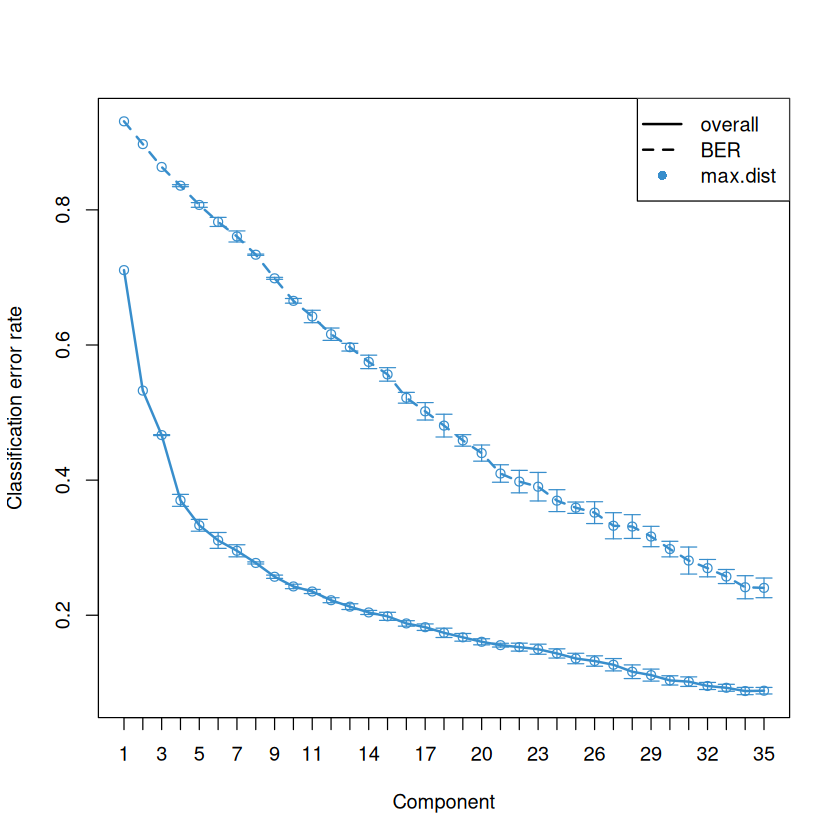

In [15]:
FOLDS     <- 3
NREPEAT   <- 10
MAX_NCOMP <- 35
KEEP_X    <- 200
DIST      <- "max.dist"
bpparam <- MulticoreParam(workers = parallel::detectCores() - 1)

gex_prelim <- splsda(X_gex_train, Y_train,
                     ncomp = MAX_NCOMP,
                     keepX = rep(KEEP_X, MAX_NCOMP))
gex_perf   <- perf(gex_prelim,
                   validation  = "Mfold",
                   folds       = FOLDS,
                   nrepeat     = NREPEAT,
                   dist        = DIST,
                   BPPARAM     = bpparam,
                   progressBar = FALSE)

# Plot BER across all components to see the curve shape
plot(gex_perf, criterion = "BER")
saveRDS(gex_perf,    file.path(OUTPUT_DIR, "gex_perf.rds"))

In [16]:
# ============================================================
# DNAm
# ============================================================
dnam_prelim <- splsda(X_dnam_train, Y_train,
                      ncomp = MAX_NCOMP,
                      keepX = rep(KEEP_X, MAX_NCOMP))
dnam_perf   <- perf(dnam_prelim,
                    validation  = "Mfold",
                    folds       = FOLDS,
                    nrepeat     = NREPEAT,
                    dist        = DIST,
                    BPPARAM     = bpparam,
                    progressBar = FALSE)
plot(dnam_perf, criterion = "BER")
saveRDS(dnam_perf,   file.path(OUTPUT_DIR, "dnam_perf.rds"))

Design matrix has changed to include Y; each block will be
            linked to Y.



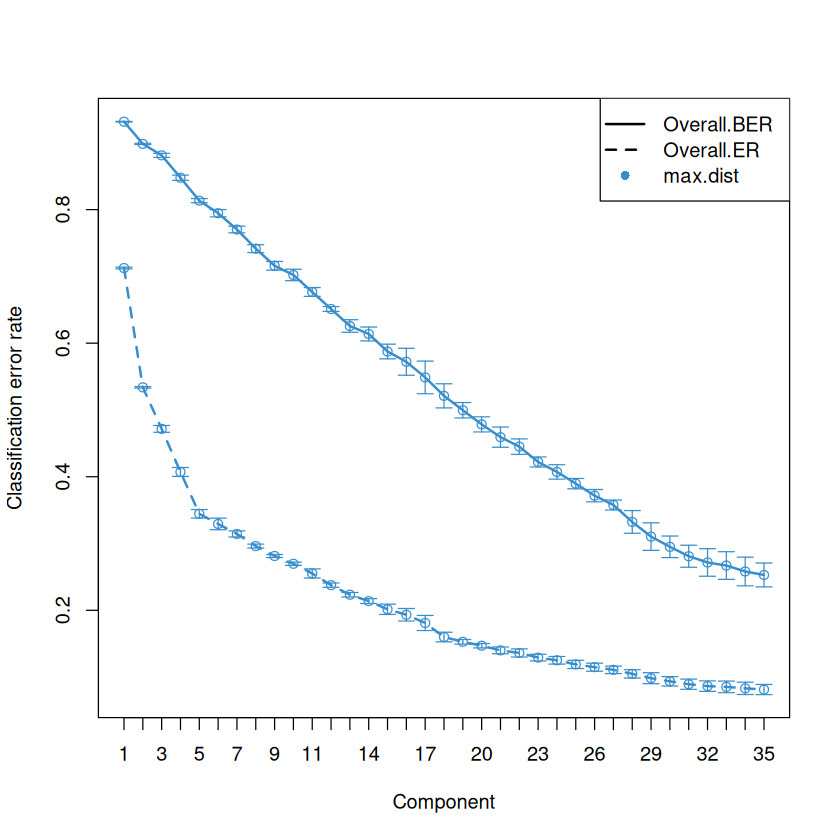

In [ ]:
# ============================================================
# DIABLO
# ============================================================
design       <- matrix(0.1, nrow = 2, ncol = 2,
                       dimnames = list(c("GEX","DNAm"), c("GEX","DNAm")))
diag(design) <- 0

blocks_train <- list(GEX = X_gex_train, DNAm = X_dnam_train)

diablo_prelim <- block.splsda(X      = blocks_train,
                               Y      = Y_train,
                               ncomp  = MAX_NCOMP,
                               keepX  = list(GEX  = rep(KEEP_X, MAX_NCOMP),
                                             DNAm = rep(KEEP_X, MAX_NCOMP)),
                               design = design)
diablo_perf   <- perf(diablo_prelim,
                      validation  = "Mfold",
                      folds       = FOLDS,
                      nrepeat     = NREPEAT,
                      dist        = DIST,
                      BPPARAM     = bpparam,
                      progressBar = FALSE)
plot(diablo_perf, criterion = "BER")
saveRDS(diablo_perf, file.path(OUTPUT_DIR, "diablo_perf.rds"))

In [ ]:
# ============================================================
# Extract optimal ncomp for each
# ============================================================
ncomp_gex    <- gex_perf$choice.ncomp["BER", "max.dist"]
ncomp_dnam   <- dnam_perf$choice.ncomp["BER", "max.dist"]
ncomp_diablo <- diablo_perf$choice.ncomp$WeightedVote["Overall.BER", 1]

cat("Optimal ncomp — GEX:", ncomp_gex,
    " DNAm:", ncomp_dnam,
    " DIABLO:", ncomp_diablo, "\n")

[1] 23

In [ ]:
# GEX
cat("=== GEX BER per component ===\n")
print(round(gex_perf$error.rate$BER[, "max.dist"], 3))

# DNAm
cat("\n=== DNAm BER per component ===\n")
print(round(dnam_perf$error.rate$BER[, "max.dist"], 3))

# DIABLO
cat("\n=== DIABLO BER per component ===\n")
diablo_ber <- colMeans(diablo_perf$WeightedVote.error.rate$max.dist)
print(round(diablo_ber, 3))

=== GEX BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.931  0.897  0.865  0.842  0.805  0.778  0.742  0.726  0.696  0.671  0.662 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.652  0.637  0.603  0.582  0.574  0.541  0.539  0.528  0.519  0.496  0.468 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.460  0.449  0.418  0.401  0.394  0.365  0.356  0.332  0.310  0.298  0.285 
comp34 comp35 
 0.275  0.268 

=== DNAm BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.932  0.901  0.891  0.860  0.825  0.815  0.799  0.755  0.725  0.696  0.673 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.645  0.618  0.597  0.575  0.558  0.529  0.497  0.471  0.450  0.438  0.411 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.413  0.386  0.365  0.359  0.336  0.335  0.305  

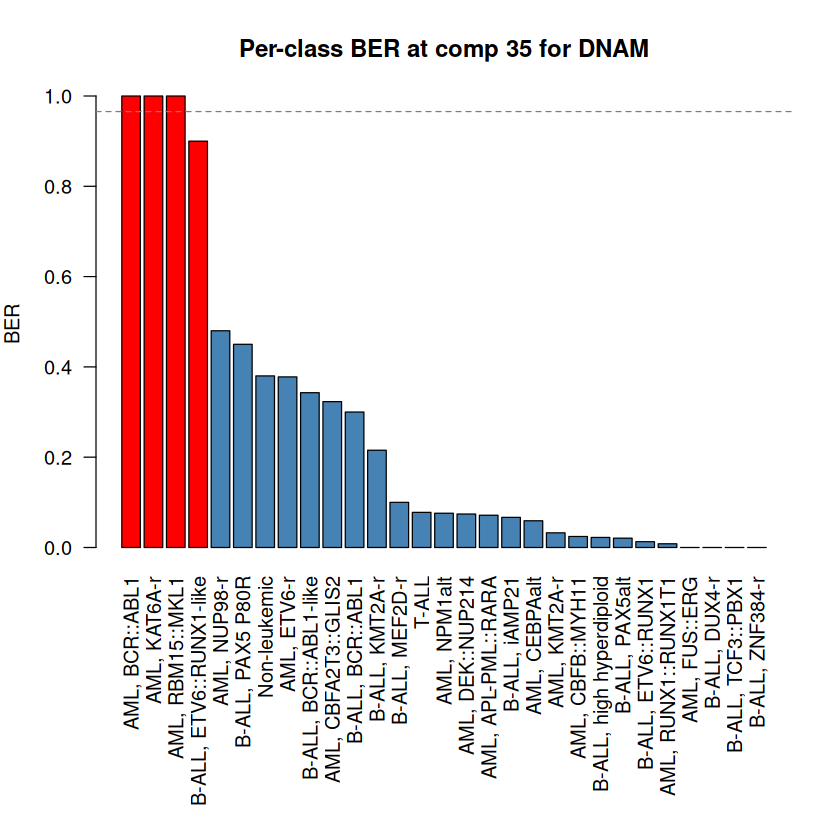

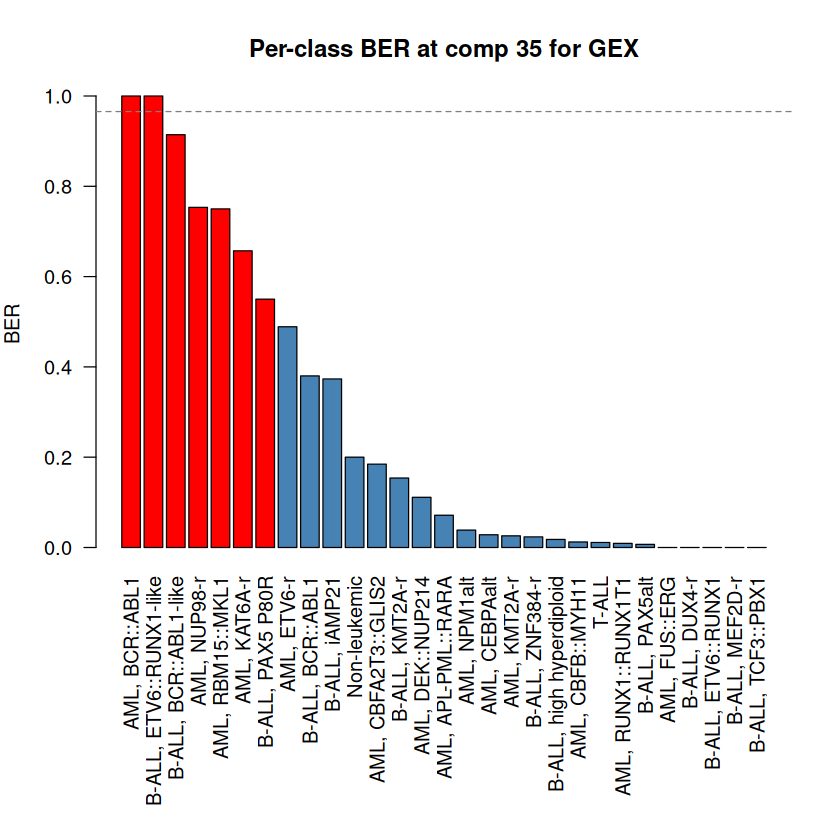

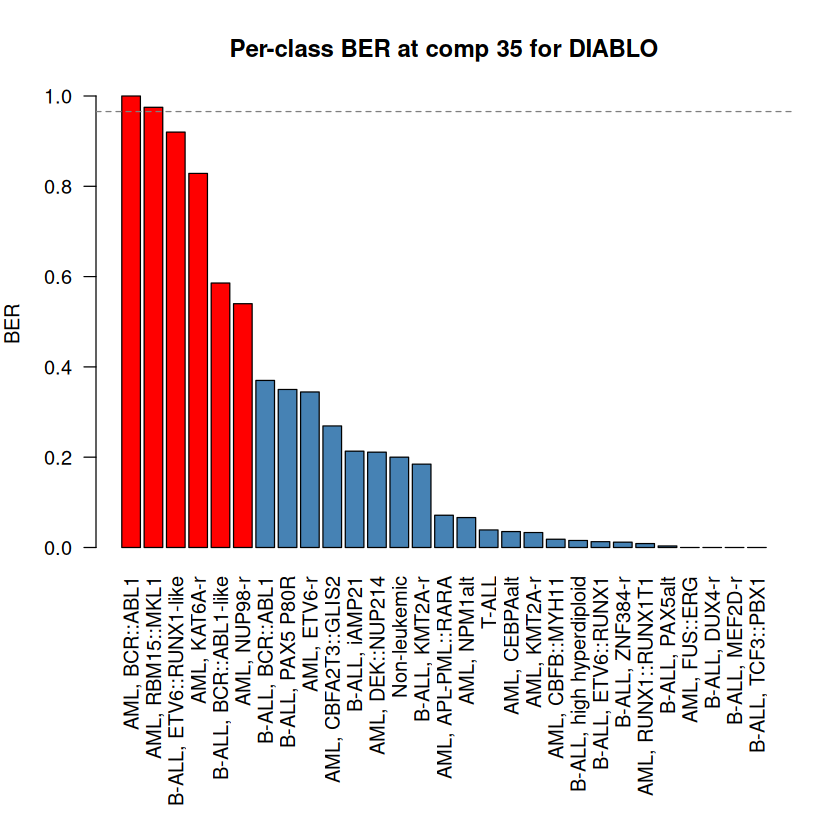

In [ ]:
comp_num <- 35

dnam_ber   <- dnam_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
gex_ber    <- gex_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
diablo_ber <- rowMeans(cbind(
  diablo_perf$error.rate.per.class$GEX$max.dist[, paste0("comp", comp_num)],
  diablo_perf$error.rate.per.class$DNAm$max.dist[, paste0("comp", comp_num)]
))

plot_per_class_ber <- function(ber, comp_num, model_name) {
  ber_sorted <- sort(ber, decreasing = TRUE)
  par(mar = c(12, 4, 4, 2))  # bottom, left, top, right
  barplot(
    ber_sorted,
    las = 2,
    ylab = "BER",
    main = paste("Per-class BER at comp", comp_num, "for", model_name),
    col = ifelse(ber_sorted > 0.5, "red", "steelblue")
  )
  abline(h = 1 - 1/nlevels(Y_train), lty = 2, col = "grey50")
}

# Sort and view
plot_per_class_ber(dnam_ber, comp_num, "DNAM")
plot_per_class_ber(gex_ber, comp_num, "GEX")
plot_per_class_ber(diablo_ber, comp_num, "DIABLO")
